# Midterm 2, problem

Midterm 2 (clustering), the larger problem, on a country dataset (country-data.csv): standardise, PCA with 5 components and its information loss, complete-linkage agglomerative clustering with the silhouette for 2 to 20 clusters, and a 4-cluster solution.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

Import the data

In [2]:
data = pd.read_csv("./country-data.csv")

Preprocess the data

In [3]:
numerical_data = data.drop("Country", axis=1)

First we separate the country column from the data
Subtract the mean and divide by the standard deviation

In [4]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler = scaler.fit(numerical_data)
transformed = pd.DataFrame(scaler.transform(numerical_data), columns=["Population","Area","PopulationDensity","Coastline","Migration","InfantMortality","GDP","Literacy","Phones","Birthrate","Deathrate"])

Use PCA to reduce the dimensionality of the data

In [5]:
from sklearn.decomposition import PCA
pca = PCA()
pca = pca.fit(transformed)
pca_transformed = pca.transform(transformed)
eigenvalues = pca.explained_variance_
eigenvectors = pca.components_

The plot below shows that the information is in the first 5
principal components

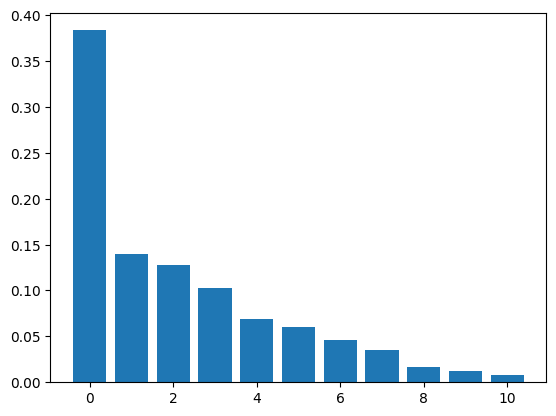

In [6]:
plt.bar(range(len(eigenvalues)), eigenvalues/sum(eigenvalues))
plt.show()

Apply PCA and keep the first 5 principal components

In [7]:
pca = PCA(n_components=5)
pca = pca.fit(transformed)
pca_transformed = pd.DataFrame(pca.transform(transformed))

In [8]:
pca_inverse = pd.DataFrame(pca.inverse_transform(pca_transformed.to_numpy()), columns=numerical_data.columns)

We confirm that we kept most of the information
The information loss is info_loss = 0.178354752218584, about 18%

In [9]:
info_loss = 1 - (eigenvalues[0] + eigenvalues[1] + eigenvalues[2] + eigenvalues[3] + eigenvalues[4])/sum(eigenvalues)  
print(info_loss)

0.178354752218584


Modelling

In [10]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram
from sklearn.metrics import silhouette_score

slc = []
for i in range(2, 21):
    clustering = AgglomerativeClustering(n_clusters=i, linkage="complete").fit(pca_inverse)
    slc.append(silhouette_score(pca_inverse, clustering.labels_))

We observe that the silhouette value decreases as the number of clusters grows
Therefore it is best to group the countries into at most four clusters

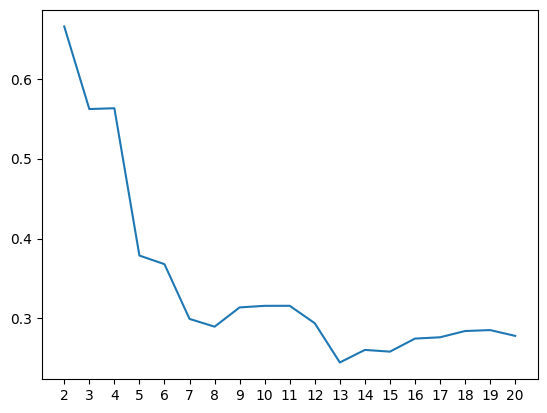

In [11]:
plt.plot(range(2, 21), slc)
plt.xticks(range(2, 21), range(2, 21))
plt.show()

In [12]:
clustering = AgglomerativeClustering(n_clusters=4, linkage="complete").fit(pca_inverse)